# Práctica 2 EDA — Rol D: Imputación de valores perdidos y outliers

**Sección 4 y 5 de la práctica.** Este notebook:

1. **Diagnostica** los valores perdidos (cuántos, dónde y si su ausencia es aleatoria: MCAR / MAR / MNAR).
2. **Compara 6 estrategias de imputación** en Titanic con el mismo modelo y evaluación del equipo.
3. **Detecta outliers** con la regla IQR (Tukey) en ambos datasets y revisa si están relacionados con la clase.
4. **Compara estrategias de outliers**: no tratar, winsorizar (IQR y percentiles 1–99), transformación `log1p`
   y eliminar filas de train.
5. **Recomienda** una configuración por dataset para el notebook final (Rol A).

Todas las transformaciones viven en `src/rol_d.py` y se ajustan **solo con train** dentro de un `Pipeline`.

### Uso de IA generativa
Se usó Claude para generar la estructura inicial del notebook y de `src/rol_d.py`.
El código fue revisado y ejecutado por el integrante del Rol D, quien puede explicarlo.

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.utils import (RANDOM_STATE, DATASETS, cargar_datos, dividir, pipeline_base,
                       evaluar, guardar_resultados, RAIZ)
from src.rol_d import (tabla_faltantes, tabla_outliers, limites_iqr, pipeline_d,
                       preprocesador_d, EliminarOutliersTrain, ImputadorPorGrupo)

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)
FIG = RAIZ / "figuras"; FIG.mkdir(exist_ok=True)
METRICAS = ["experimento", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "TP", "FP", "FN", "TN"]

## Parte 1 — Diagnóstico de valores perdidos

El Rol B (profiling) dejó sus recomendaciones para esta sección en `resultados/rol_b_para_rol_d.csv`;
aquí se ponen a prueba con el modelo.

In [2]:
ruta_b = RAIZ / "resultados" / "rol_b_para_rol_d.csv"
if ruta_b.exists():
    display(pd.read_csv(ruta_b, encoding="utf-8-sig")[["dataset", "columna", "tratamiento", "justificacion"]])

,dataset,columna,tratamiento,justificacion
0,titanic,Age,Imputar,Comparar media vs mediana (ajustadas solo con ...
1,titanic,Embarked,Imputar,Moda ('S') vs categoría 'Desconocido'. Solo 2 ...
2,titanic,Cabin,No imputar el valor,77 % de nulos: no hay base para inventar camar...
3,titanic,Fare,Winsorizar,Asimetría alta y 13 % de outliers IQR. Compara...
4,titanic,Parch,No winsorizar con IQR,Conteo discreto con IQR = 0: la regla marcaría...
5,fraud,Amount,Winsorizar,Asimetría ≈ 17. p1–p99 es razonable; IQR recor...
6,fraud,V14,No winsorizar (aplica a V1–V28),Los outliers son la señal de fraude: el 87 % d...


In [3]:
titanic = cargar_datos("titanic")
print("Titanic:", titanic.shape)
tabla_faltantes(titanic)

Titanic: (891, 12)


,faltantes,%,tipo
Cabin,687,77.1044,str
Age,177,19.8653,float64
Embarked,2,0.2245,str


In [4]:
try:
    fraud = cargar_datos("fraud")
    print("Credit Card Fraud:", fraud.shape)
    print("Valores perdidos totales:", int(fraud.isna().sum().sum()))
    HAY_FRAUD = True
except FileNotFoundError as e:
    print(e); HAY_FRAUD = False

Credit Card Fraud: (284807, 31)
Valores perdidos totales: 0


**Lectura:**

| Columna | % perdido | Decisión |
|---|---|---|
| `Cabin` | ~77 % | Demasiados huecos para imputar un valor creíble. La línea base ya la excluye; se evalúa usar solo el **indicador** `tiene_cabina` (¿el pasajero tenía cabina registrada?). |
| `Age` | ~20 % | Variable relevante (niños primero). Se **imputa**; es el foco de la comparación. |
| `Embarked` | 0.2 % (2 filas) | Se imputa con la **moda** (impacto despreciable). |
| Credit Card Fraud | 0 % | **No requiere imputación.** El trabajo del Rol D en este dataset se centra en outliers. |

### ¿Los faltantes de `Age` son aleatorios?
Si `Age` falta con la misma probabilidad para todos (MCAR) cualquier imputación simple sirve. Si depende de
otras variables (MAR), conviene imputar **condicionado** a ellas.

In [5]:
t = titanic.assign(age_faltante=titanic["Age"].isna())
mar = pd.concat({
    "% Age faltante por Pclass": t.groupby("Pclass")["age_faltante"].mean() * 100,
}, axis=1)
display(mar)
display((t.groupby("Sex")["age_faltante"].mean() * 100).rename("% Age faltante por Sex").to_frame())
display(t.groupby("age_faltante")["Survived"].mean().rename("tasa de supervivencia").to_frame())

,% Age faltante por Pclass
Pclass,
1,13.8889
2,5.9783
3,27.6986


,% Age faltante por Sex
Sex,
female,16.8790
male,21.4905


,tasa de supervivencia
age_faltante,
False,0.4062
True,0.2938


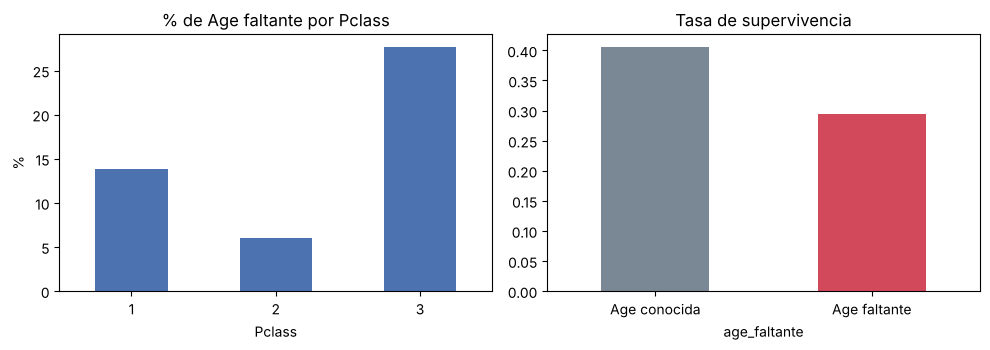

In [6]:
# Pregunta: ¿la ausencia de Age depende de la clase del pasajero?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
(t.groupby("Pclass")["age_faltante"].mean() * 100).plot.bar(ax=axes[0], color="#4c72b0")
axes[0].set_title("% de Age faltante por Pclass"); axes[0].set_ylabel("%"); axes[0].tick_params(axis="x", rotation=0)
t.groupby("age_faltante")["Survived"].mean().rename({False: "Age conocida", True: "Age faltante"}) \
    .plot.bar(ax=axes[1], color=["#7a8794", "#d1495b"])
axes[1].set_title("Tasa de supervivencia"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG / "d_faltantes_age.png", dpi=150); plt.show()

**Conclusión:** `Age` falta mucho más en **3ª clase** (~25 %) que en 1ª y 2ª, y quienes no tienen edad
registrada sobrevivieron menos (~29 % vs ~41 %). La ausencia **no es MCAR**; es al menos **MAR** (depende de
`Pclass`). Por eso se prueban imputaciones condicionadas (mediana por `Pclass`/`Sex`, KNN, iterativa) y un
**indicador de faltante**, que deja al modelo aprovechar que "no tener edad" ya es información.

## Parte 2 — Comparación de estrategias de imputación (Titanic)

Mismo split (70/30 estratificado, semilla 42), mismo modelo (`LogisticRegression`) y mismas métricas.
Solo cambia **cómo se rellenan** los valores perdidos.

| Estrategia | Idea | Riesgo |
|---|---|---|
| Eliminar filas | Quitar de train las filas con `Age` nula | Pierde ~20 % de los datos y sesga hacia 1ª/2ª clase |
| Media | Rellenar con el promedio de train | Sensible a outliers; reduce la varianza |
| Mediana (línea base) | Rellenar con la mediana de train | Robusta, pero ignora el contexto |
| Mediana por grupo | Mediana de `Age` por `Pclass` × `Sex` | Necesita grupos con datos suficientes |
| KNN (k=5) | Promedio de los 5 pasajeros más parecidos | Depende de la escala → se estandariza antes |
| Iterativa (MICE) | Regresión de `Age` sobre las demás variables | Más costosa; puede sobreajustar |
| + indicador | Cualquiera de las anteriores + columna `Age_faltante` | Una columna más |

> Test **siempre** se imputa: en producción no se puede descartar un pasajero sin edad.

In [7]:
X_train, X_test, y_train, y_test = dividir(titanic, "titanic")
print("Age faltante en train:", X_train["Age"].isna().sum(), "| en test:", X_test["Age"].isna().sum())

res_imp = []
res_imp.append(evaluar(pipeline_base(X_train), X_train, y_train, X_test, y_test,
                       nombre="Línea base (mediana)", mostrar=False))

# Eliminar filas con Age nula SOLO en train
m = X_train["Age"].notna()
res_imp.append(evaluar(pipeline_d(X_train[m]), X_train[m], y_train[m], X_test, y_test,
                       nombre="Eliminar filas (train)", mostrar=False))

for nombre, kw in [
    ("Media",                  dict(imputar_num="mean")),
    ("Mediana por Pclass×Sex", dict(imputar_num="grupo")),
    ("KNN (k=5)",              dict(imputar_num="knn")),
    ("Iterativa (MICE)",       dict(imputar_num="iterativo")),
    ("Mediana + indicador",    dict(imputar_num="median", indicador=True)),
    ("Grupo + indicador",      dict(imputar_num="grupo", indicador=True)),
]:
    res_imp.append(evaluar(pipeline_d(X_train, **kw), X_train, y_train, X_test, y_test,
                           nombre=nombre, mostrar=False))

Age faltante en train: 119 | en test: 58


In [8]:
# Variante: Cabin -> indicador "tiene_cabina" (en vez de descartar la columna)
def con_cabina(df):
    return df.assign(tiene_cabina=df["Cabin"].notna().astype(int))

Xc_train, Xc_test, _, _ = dividir(con_cabina(titanic), "titanic")
res_imp.append(evaluar(pipeline_d(Xc_train, imputar_num="grupo", indicador=True),
                       Xc_train, y_train, Xc_test, y_test,
                       nombre="Grupo + indicador + tiene_cabina", mostrar=False))

# Variante sugerida por el Rol B: mediana de Age por título del nombre (Master ≈ niño)
def con_titulo(df):
    t = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
    t = t.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    t = t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Raro")
    return df.assign(Titulo=t)

Xt_train, Xt_test, _, _ = dividir(con_titulo(titanic), "titanic")
res_imp.append(evaluar(pipeline_d(Xt_train, imputar_num="grupo", grupos=("Titulo",), indicador=True),
                       Xt_train, y_train, Xt_test, y_test,
                       nombre="Mediana por Título + indicador", mostrar=False))

tabla_imp = guardar_resultados(res_imp, "imputacion_titanic.csv")[METRICAS]
tabla_imp.style.format(precision=4).highlight_max(subset=["accuracy", "f1", "roc_auc", "pr_auc"], color="#c7e9c0")

,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Línea base (mediana),0.7985,0.7475,0.7184,0.7327,0.8495,0.8036,74,25,29,140
1,Eliminar filas (train),0.7761,0.7172,0.6893,0.7030,0.8526,0.8005,71,28,32,137
2,Media,0.8060,0.7576,0.7282,0.7426,0.8489,0.8030,75,24,28,141
3,Mediana por Pclass×Sex,0.8097,0.7653,0.7282,0.7463,0.8503,0.8037,75,23,28,142
4,KNN (k=5),0.8022,0.7604,0.7087,0.7337,0.8492,0.8021,73,23,30,142
5,Iterativa (MICE),0.8134,0.7732,0.7282,0.7500,0.8512,0.8051,75,22,28,143
6,Mediana + indicador,0.7985,0.7526,0.7087,0.7300,0.8510,0.8039,73,24,30,141
7,Grupo + indicador,0.8097,0.7653,0.7282,0.7463,0.8503,0.8037,75,23,28,142
8,Grupo + indicador + tiene_cabina,0.8134,0.7624,0.7476,0.7549,0.8473,0.7913,77,24,26,141
9,Mediana por Título + indicador,0.8321,0.7900,0.7670,0.7783,0.8805,0.8516,79,21,24,144


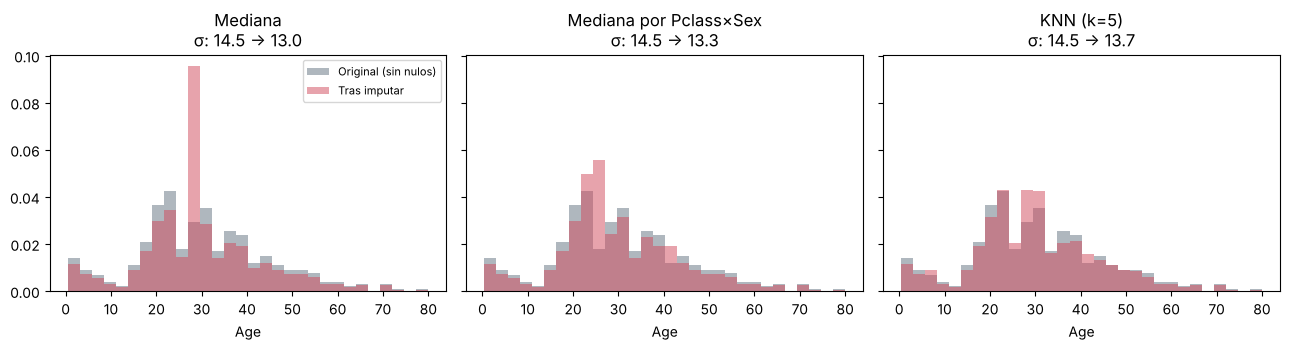

In [9]:
# Pregunta: ¿cómo cambia la distribución de Age según la imputación?
from src.rol_d import _imputador_num
from sklearn.preprocessing import StandardScaler
num = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
original = X_train["Age"].dropna()
imputados = {
    "Mediana": X_train["Age"].fillna(X_train["Age"].median()),
    "Mediana por Pclass×Sex": ImputadorPorGrupo().fit(X_train).transform(X_train)["Age"],
}
from sklearn.impute import KNNImputer
esc = StandardScaler().fit(X_train[num])
knn = esc.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(esc.transform(X_train[num])))
imputados["KNN (k=5)"] = pd.Series(knn[:, 1], index=X_train.index)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (n, s) in zip(axes, imputados.items()):
    ax.hist(original, bins=30, alpha=.6, label="Original (sin nulos)", color="#7a8794", density=True)
    ax.hist(s, bins=30, alpha=.5, label="Tras imputar", color="#d1495b", density=True)
    ax.set_title(f"{n}\nσ: {original.std():.1f} → {s.std():.1f}"); ax.set_xlabel("Age")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "d_distribucion_age_imputada.png", dpi=150); plt.show()

**Lectura de la gráfica:** la mediana global crea un **pico artificial** en ~28 años y reduce la desviación
estándar: "aplasta" la variabilidad real. La mediana por grupo reparte los valores en varios picos (uno por
combinación `Pclass`×`Sex`) y KNN produce una distribución más parecida a la original.

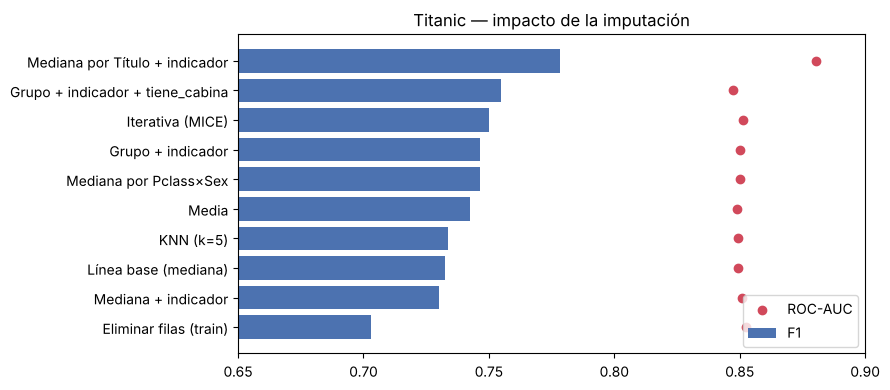

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla_imp.sort_values("f1")
ax.barh(orden["experimento"], orden["f1"], color="#4c72b0", label="F1")
ax.scatter(orden["roc_auc"], orden["experimento"], color="#d1495b", zorder=3, label="ROC-AUC")
ax.set_xlim(0.65, 0.90); ax.set_title("Titanic — impacto de la imputación"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "d_metricas_imputacion.png", dpi=150); plt.show()

In [11]:
mejor = tabla_imp.loc[tabla_imp["f1"].idxmax()]
base = tabla_imp.iloc[0]
print(f"Mejor F1: {mejor['experimento']}  F1={mejor['f1']:.4f}  (base {base['f1']:.4f}, Δ={mejor['f1']-base['f1']:+.4f})")
print(f"Rango de F1 entre estrategias: {tabla_imp['f1'].min():.4f} – {tabla_imp['f1'].max():.4f}")

Mejor F1: Mediana por Título + indicador  F1=0.7783  (base 0.7327, Δ=+0.0457)
Rango de F1 entre estrategias: 0.7030 – 0.7783


**Conclusiones de imputación:**

* Las diferencias entre estrategias son **pequeñas** (pocos puntos de F1 sobre 268 pasajeros de test): con
  regresión logística, `Age` aporta menos que `Sex` y `Pclass`, así que cómo se rellena no cambia mucho el resultado.
* **Eliminar filas** es la opción más débil conceptualmente: descarta ~20 % de train, sobre todo de 3ª clase,
  y aun así hay que imputar en test.
* Las imputaciones **condicionadas** (grupo, KNN, MICE) preservan mejor la distribución de `Age` que la mediana
  global, aunque eso no siempre se traduzca en más F1.
* Agregar el **indicador de faltante** (y `tiene_cabina`) aprovecha que los datos son MAR: el hecho de que falte
  el dato se relaciona con la supervivencia.
* En esta corrida, **mediana por grupo** y **MICE** superan a la mediana global (F1 ≈ 0.746–0.750 vs 0.733),
  y agregar **`tiene_cabina`** sube a F1 ≈ 0.755. Eliminar filas es la peor (F1 ≈ 0.703).
* La variante sugerida por el Rol B, **mediana de `Age` por título** (`Mr`, `Mrs`, `Miss`, `Master`, `Raro`), es la
  mejor por mucho: F1 0.778, ROC-AUC 0.880 y PR-AUC 0.852. El título es mejor guía de la edad que `Pclass`×`Sex`
  (todo `Master` es niño), **pero ojo**: parte de la mejora viene de que `Titulo` también entra como atributo
  nuevo al modelo, no solo de imputar mejor.
* **Recomendación para el notebook final:** imputar `Age` con la **mediana por título + indicador de faltante**
  (agregando la columna `Titulo`). Si el equipo prefiere no agregar atributos, la alternativa es
  mediana por `Pclass`×`Sex` + indicador.

### Imputación de una variable categórica: `Embarked`

La práctica pide comparar al menos una variable numérica **y una categórica**. `Embarked` (puerto de embarque)
tiene 2 valores perdidos. Se comparan dos estrategias, ajustadas solo con train:

* **A · Moda:** rellenar con el puerto más frecuente en train (`S`, Southampton).
* **B · Categoría "Desconocido":** crear una categoría nueva; el one-hot le da su propia columna, así el modelo
  no supone a qué puerto pertenecen.

In [12]:
# Pregunta: ¿cambia algo imputar Embarked con la moda o con la categoría "Desconocido"?
import pandas as pd
from sklearn.pipeline import Pipeline
sys.path.append("..")
from src.utils import cargar_datos, dividir, preprocesador_minimo, modelo_base, evaluar, guardar_resultados

titanic = cargar_datos("titanic")
X_train, X_test, y_train, y_test = dividir(titanic, "titanic")

print("Nulos de Embarked → train:", X_train["Embarked"].isna().sum(), "| test:", X_test["Embarked"].isna().sum())

# Distribución de Embarked en train: original vs. cada estrategia
moda = X_train["Embarked"].mode()[0]                     # moda calculada SOLO con train
dist = pd.DataFrame({
    "Original (con NaN)":   X_train["Embarked"].value_counts(dropna=False),
    "A · Moda":             X_train["Embarked"].fillna(moda).value_counts(),
    "B · 'Desconocido'":    X_train["Embarked"].fillna("Desconocido").value_counts(),
}).fillna(0).astype(int)
display(dist)
print(f"Moda de train = '{moda}'")

# Impacto en el modelo (misma imputación numérica: mediana)
res_cat = []
for nombre, estrategia in [("A · Moda", "most_frequent"), ("B · 'Desconocido'", "constant")]:
    modelo = Pipeline([("prep", preprocesador_minimo(X_train, imputar_cat=estrategia)),
                       ("modelo", modelo_base())])
    res_cat.append(evaluar(modelo, X_train, y_train, X_test, y_test, nombre=f"Embarked · {nombre}"))
guardar_resultados(res_cat, "imputacion_categorica_titanic.csv")

Nulos de Embarked → train: 2 | test: 0


,Original (con NaN),A · Moda,B · 'Desconocido'
Embarked,,,
C,124,124,124
Desconocido,0,0,2
Q,53,53,53
S,444,446,444
NaN,2,0,0


Moda de train = 'S'
--- Embarked · A · Moda ---
  accuracy: 0.7985
 precision: 0.7475
    recall: 0.7184
        f1: 0.7327
   roc_auc: 0.8495
    pr_auc: 0.8036
Matriz de confusión  TP=74  FP=25  FN=29  TN=140

--- Embarked · B · 'Desconocido' ---
  accuracy: 0.7985
 precision: 0.7475
    recall: 0.7184
        f1: 0.7327
   roc_auc: 0.8495
    pr_auc: 0.8036
Matriz de confusión  TP=74  FP=25  FN=29  TN=140



,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Embarked · A · Moda,0.7985,0.7475,0.7184,0.7327,0.8495,0.8036,74,25,29,140
1,Embarked · B · 'Desconocido',0.7985,0.7475,0.7184,0.7327,0.8495,0.8036,74,25,29,140


**Conclusión (categórica):** las dos estrategias dan **métricas idénticas** (F1 = 0.733). No es un error: los dos
nulos (dos pasajeras de 1ª clase con la misma cabina `B28` y tarifa 80) cayeron en train y test no tiene nulos,
así que la estrategia solo cambia 2 de 623 filas de entrenamiento. **Con tan pocos faltantes, la estrategia
categórica no importa.** Se elige la **moda** porque no agrega al one-hot una columna casi vacía de la que el
modelo no puede aprender nada. "Desconocido" sería preferible si la ausencia fuera frecuente o informativa,
como en `Cabin` (77 % de nulos).

## Parte 3 — Detección de outliers (regla IQR de Tukey)

Un valor es atípico si cae fuera de **[Q1 − 1.5·IQR, Q3 + 1.5·IQR]**. Se calcula **solo con train**.
La última columna muestra qué % de los outliers pertenece a la clase positiva, comparado con el % global:
si es mucho mayor, **el outlier es señal, no ruido**.

In [13]:
out_tit = tabla_outliers(X_train, y_train, columnas=["Age", "SibSp", "Parch", "Fare"])
out_tit

,columna,lim_inf,lim_sup,n_outliers,%_outliers,min,max,asimetria,%_clase1_en_outliers,%_clase1_global
0,Parch,0.0000,0.0000,142,22.7929,0.0000,6.0000,2.9980,53.5211,38.3628
1,Fare,-25.2605,63.1563,77,12.3596,0.0000,512.3292,4.9817,74.0260,38.3628
2,SibSp,-1.5000,2.5000,25,4.0128,0.0000,8.0000,3.7665,12.0000,38.3628
3,Age,-6.0000,66.0000,6,0.9631,0.4200,80.0000,0.3660,16.6667,38.3628


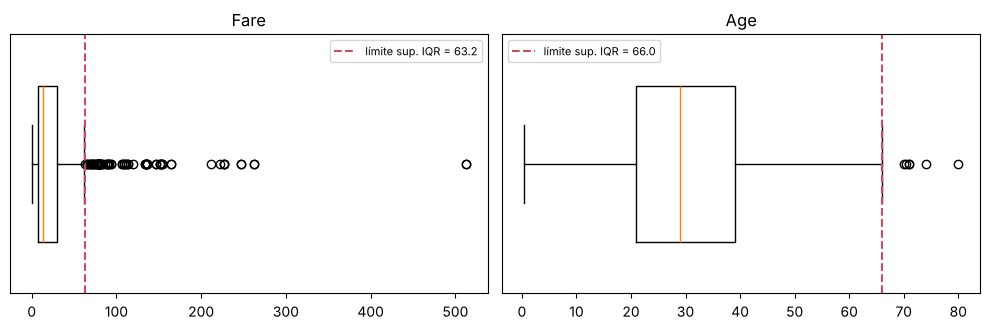

In [14]:
# Pregunta: ¿dónde están los valores extremos de Fare y Age?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, c in zip(axes, ["Fare", "Age"]):
    ax.boxplot(X_train[c].dropna(), vert=False, widths=.6)
    li, ls = limites_iqr(X_train[c].dropna())
    ax.axvline(ls, color="#d1495b", ls="--", label=f"límite sup. IQR = {ls:.1f}")
    ax.set_title(c); ax.legend(fontsize=8); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "d_boxplots_titanic.png", dpi=150); plt.show()

**Lectura (Titanic):**

* `Fare` tiene la cola más larga (máximo 512 vs mediana ~14) y asimetría muy alta. Esos boletos caros son
  **reales** (1ª clase), no errores de captura, y los pasajeros que los pagaron sobrevivieron más.
* `Parch` tiene Q1 = Q3 = 0, por lo que **cualquier** valor ≥ 1 sale como "outlier": la regla IQR **no tiene
  sentido** en variables de conteo con mayoría de ceros. Lo mismo ocurre, en menor grado, con `SibSp`.
* Por eso el tratamiento se aplica **solo a `Fare`** (y a `Age` como comparación).

In [15]:
if HAY_FRAUD:
    Xf_train, Xf_test, yf_train, yf_test = dividir(fraud, "fraud")
    out_fr = tabla_outliers(Xf_train, yf_train)
    display(out_fr.head(12))
    print("Columnas con más del 5 % de outliers:", (out_fr["%_outliers"] > 5).sum(), "de", len(out_fr))

,columna,lim_inf,lim_sup,n_outliers,%_outliers,min,max,asimetria,%_clase1_en_outliers,%_clase1_global
0,V27,-0.3134,0.3338,27466,13.7768,-22.5657,31.6122,-0.6900,0.8811,0.1725
1,Amount,-102.0750,185.2450,22301,11.1861,0.0000,25691.1600,18.8886,0.2690,0.1725
2,V28,-0.2497,0.2750,21300,10.6840,-15.4301,33.8478,10.6180,0.8873,0.1725
3,V20,-0.7290,0.6502,19576,9.8192,-54.4977,39.4209,-2.2264,0.6641,0.1725
4,V8,-1.0116,1.1301,16847,8.4504,-73.2167,20.0072,-8.8515,0.9853,0.1725
5,V6,-2.5204,2.1504,16058,8.0546,-26.1605,73.3016,2.0255,0.5916,0.1725
6,V23,-0.6270,0.6129,12991,6.5162,-44.8077,22.0835,-6.1687,0.7852,0.1725
7,V12,-1.9386,2.1534,10722,5.3781,-18.6837,7.8484,-2.3592,2.6861,0.1725
8,V21,-0.8509,0.8091,10116,5.0741,-34.8304,27.2028,3.4522,1.6607,0.1725
9,V14,-1.8030,1.8680,9984,5.0079,-19.2143,10.5268,-2.0261,3.0649,0.1725


Columnas con más del 5 % de outliers: 10 de 30


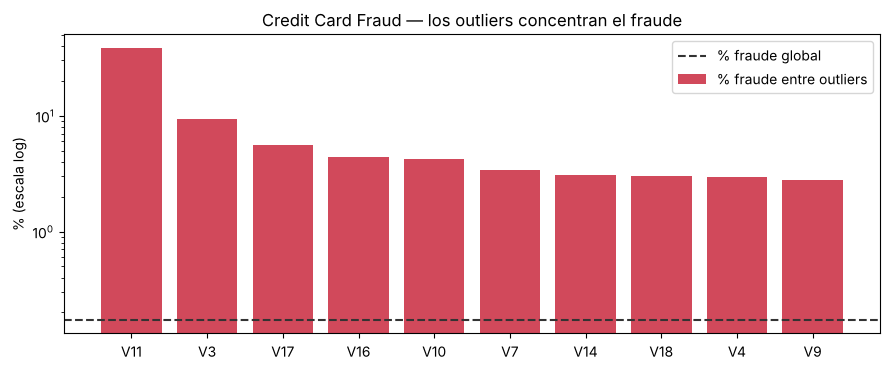

Si se eliminaran las filas con algún outlier IQR en train: quedan 102,334 de 199,364 filas
  fraudes: 9 de 344  -> se perdería el 97.4 % de los fraudes


In [16]:
if HAY_FRAUD:
    # Pregunta: entre los outliers, ¿qué tan concentrado está el fraude?
    top = out_fr.dropna().sort_values("%_clase1_en_outliers", ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.bar(top["columna"], top["%_clase1_en_outliers"], color="#d1495b", label="% fraude entre outliers")
    ax.axhline(top["%_clase1_global"].iloc[0], color="#333", ls="--", label="% fraude global")
    ax.set_yscale("log"); ax.set_ylabel("% (escala log)"); ax.legend()
    ax.set_title("Credit Card Fraud — los outliers concentran el fraude")
    plt.tight_layout(); plt.savefig(FIG / "d_fraude_en_outliers.png", dpi=150); plt.show()

    filas_out = EliminarOutliersTrain(list(Xf_train.columns)).aplicar(Xf_train, yf_train)
    print(f"Si se eliminaran las filas con algún outlier IQR en train: quedan {len(filas_out[0]):,} de {len(Xf_train):,} filas")
    print(f"  fraudes: {int(filas_out[1].sum())} de {int(yf_train.sum())}  -> se perdería el "
          f"{100*(1 - filas_out[1].sum()/yf_train.sum()):.1f} % de los fraudes")

**Lectura (Credit Card Fraud):**

* `V1`–`V28` son componentes de PCA (ya centradas) con colas pesadas; varias tienen un % importante de outliers.
* En las columnas más discriminantes, la proporción de fraude **entre los outliers** es muchísimo mayor que la
  global (~0.17 %). Los outliers **son la señal** que el modelo necesita.
* Eliminar filas atípicas de train borraría el **97 % de los fraudes** (quedan 9 de 344): queda descartado.
* `Amount` está muy sesgada (asimetría ≈ 19, máximo 25 691) y `Time` no tiene outliers.

## Parte 4 — Comparación de tratamientos de outliers

| Estrategia | Qué hace |
|---|---|
| Sin tratar | Línea base del Rol D (imputación recomendada, sin tocar outliers) |
| Winsorizar IQR | Recorta a los límites de Tukey aprendidos en train |
| Winsorizar P1–P99 | Recorta a los percentiles 1 y 99 de train (menos agresivo) |
| `log1p` | Comprime la cola larga sin perder el orden de los valores |
| Eliminar filas (train) | Descarta de train las filas con outliers; test intacto |

La **winsorización no elimina filas**, solo limita el valor extremo; así el modelo sigue viendo a esos casos.

In [17]:
BASE_D = dict(imputar_num="grupo", indicador=True)   # Pclass×Sex: aísla el efecto de outliers sin el atributo Titulo
res_out = []
for nombre, kw in [
    ("Sin tratar",                    {}),
    ("Winsorizar IQR (Fare)",         dict(outliers="iqr", cols_outliers=["Fare"])),
    ("Winsorizar P1–P99 (Fare)",      dict(outliers="percentil", cols_outliers=["Fare"])),
    ("log1p (Fare)",                  dict(outliers="log", cols_outliers=["Fare"])),
    ("Winsorizar IQR (Fare, Age)",    dict(outliers="iqr", cols_outliers=["Fare", "Age"])),
    ("Winsorizar IQR (todas num.)",   dict(outliers="iqr", cols_outliers=["Age", "SibSp", "Parch", "Fare"])),
]:
    res_out.append(evaluar(pipeline_d(X_train, **BASE_D, **kw), X_train, y_train, X_test, y_test,
                           nombre=nombre, mostrar=False))

Xe, ye = EliminarOutliersTrain(["Fare"]).aplicar(X_train, y_train)
res_out.append(evaluar(pipeline_d(Xe, **BASE_D), Xe, ye, X_test, y_test,
                       nombre=f"Eliminar filas Fare (train: {len(Xe)}/{len(X_train)})", mostrar=False))

tabla_out_tit = guardar_resultados(res_out, "outliers_titanic.csv")[METRICAS]
tabla_out_tit.style.format(precision=4).highlight_max(subset=["accuracy", "f1", "roc_auc", "pr_auc"], color="#c7e9c0")

,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Sin tratar,0.8097,0.7653,0.7282,0.7463,0.8503,0.8037,75,23,28,142
1,Winsorizar IQR (Fare),0.8097,0.7600,0.7379,0.7488,0.8513,0.8030,76,24,27,141
2,Winsorizar P1–P99 (Fare),0.8134,0.7732,0.7282,0.7500,0.8502,0.8032,75,22,28,143
3,log1p (Fare),0.8060,0.7576,0.7282,0.7426,0.8527,0.8051,75,24,28,141
4,"Winsorizar IQR (Fare, Age)",0.8097,0.7600,0.7379,0.7488,0.8511,0.8022,76,24,27,141
5,Winsorizar IQR (todas num.),0.7948,0.7353,0.7282,0.7317,0.8438,0.7931,75,27,28,138
6,Eliminar filas Fare (train: 546/623),0.7761,0.6972,0.7379,0.7170,0.8347,0.7599,76,33,27,132


In [18]:
if HAY_FRAUD:
    res_fr = []
    for nombre, kw in [
        ("Sin tratar (StandardScaler)",      dict(escalador="standard")),
        ("RobustScaler",                     dict(escalador="robust")),
        ("log1p Amount + RobustScaler",      dict(escalador="robust", outliers="log", cols_outliers=["Amount"])),
        ("Winsorizar P1–P99 (todas)",        dict(outliers="percentil")),
        ("Winsorizar IQR (todas)",           dict(outliers="iqr")),
        ("Winsorizar P1–P99 solo Amount",    dict(outliers="percentil", cols_outliers=["Amount"])),
        ("Winsorizar IQR solo Amount",       dict(outliers="iqr", cols_outliers=["Amount"])),
    ]:
        res_fr.append(evaluar(pipeline_d(Xf_train, **kw), Xf_train, yf_train, Xf_test, yf_test,
                              nombre=nombre, mostrar=False))
    Xe, ye = EliminarOutliersTrain(list(Xf_train.columns)).aplicar(Xf_train, yf_train)
    if ye.nunique() == 2:
        res_fr.append(evaluar(pipeline_d(Xe), Xe, ye, Xf_test, yf_test,
                              nombre=f"Eliminar filas (train: {len(Xe):,})", mostrar=False))
    else:
        print("Eliminar filas deja train SIN fraudes: el modelo ni siquiera se puede entrenar.")
    tabla_out_fr = guardar_resultados(res_fr, "outliers_fraud.csv")[METRICAS]
    display(tabla_out_fr.style.format(precision=4)
            .highlight_max(subset=["precision", "recall", "f1", "pr_auc"], color="#c7e9c0"))

,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Sin tratar (StandardScaler),0.9991,0.8505,0.6149,0.7137,0.9567,0.7080,91,16,57,85279
1,RobustScaler,0.9991,0.8411,0.6081,0.7059,0.9552,0.7077,90,17,58,85278
2,log1p Amount + RobustScaler,0.9992,0.8545,0.6351,0.7287,0.9602,0.7128,94,16,54,85279
3,Winsorizar P1–P99 (todas),0.9994,0.8605,0.7500,0.8014,0.9653,0.7730,111,18,37,85277
4,Winsorizar IQR (todas),0.9993,0.8397,0.7432,0.7885,0.9664,0.7552,110,21,38,85274
5,Winsorizar P1–P99 solo Amount,0.9991,0.8426,0.6149,0.7109,0.9688,0.7077,91,17,57,85278
6,Winsorizar IQR solo Amount,0.9992,0.8598,0.6216,0.7216,0.9572,0.7095,92,15,56,85280
7,"Eliminar filas (train: 102,334)",0.9977,0.1343,0.0608,0.0837,0.5317,0.0313,9,58,139,85237


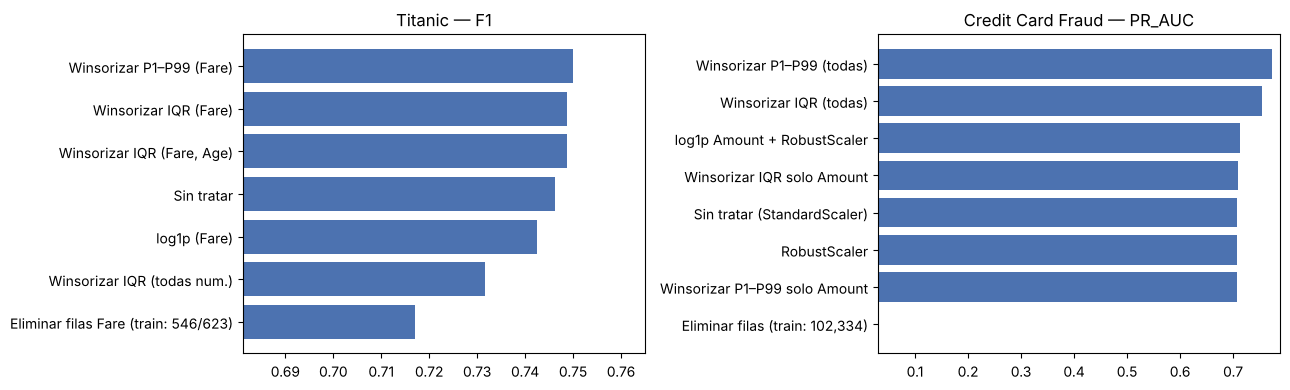

In [19]:
# Pregunta: ¿qué tratamiento conserva mejor el desempeño en cada dataset?
paneles = [("Titanic", tabla_out_tit, "f1")]
if HAY_FRAUD:
    paneles.append(("Credit Card Fraud", tabla_out_fr, "pr_auc"))
fig, axes = plt.subplots(1, len(paneles), figsize=(6.5 * len(paneles), 4))
axes = np.atleast_1d(axes)
for ax, (titulo, tabla, met) in zip(axes, paneles):
    o = tabla.sort_values(met)
    ax.barh(o["experimento"], o[met], color="#4c72b0")
    ax.set_xlim(o[met].min() * 0.95, o[met].max() * 1.02)
    ax.set_title(f"{titulo} — {met.upper()}")
plt.tight_layout(); plt.savefig(FIG / "d_metricas_outliers.png", dpi=150); plt.show()

In [20]:
def resumen(tabla, met):
    b = tabla.iloc[0]; m = tabla.loc[tabla[met].idxmax()]; p = tabla.loc[tabla[met].idxmin()]
    print(f"  base: {b['experimento']} {met}={b[met]:.4f}")
    print(f"  mejor: {m['experimento']} {met}={m[met]:.4f}  (Δ {m[met]-b[met]:+.4f})")
    print(f"  peor:  {p['experimento']} {met}={p[met]:.4f}  (Δ {p[met]-b[met]:+.4f})")
print("Titanic"); resumen(tabla_out_tit, "f1")
if HAY_FRAUD:
    print("Credit Card Fraud"); resumen(tabla_out_fr, "pr_auc")

Titanic
  base: Sin tratar f1=0.7463
  mejor: Winsorizar P1–P99 (Fare) f1=0.7500  (Δ +0.0037)
  peor:  Eliminar filas Fare (train: 546/623) f1=0.7170  (Δ -0.0293)
Credit Card Fraud
  base: Sin tratar (StandardScaler) pr_auc=0.7080
  mejor: Winsorizar P1–P99 (todas) pr_auc=0.7730  (Δ +0.0651)
  peor:  Eliminar filas (train: 102,334) pr_auc=0.0313  (Δ -0.6766)


**Conclusiones de outliers:**

* **Titanic (esta corrida):** las variantes sobre `Fare` quedan todas en F1 ≈ 0.743–0.750; `log1p` da la mejor
  ROC-AUC/PR-AUC y winsorizar P1–P99 el mejor F1. Eliminar filas (F1 ≈ 0.717) y winsorizar todas las numéricas
  (F1 ≈ 0.732) **empeoran**.

* **Por qué:** tratar `Fare` (winsorizar o `log1p`) apenas mueve las métricas: los boletos caros son datos
  válidos y la regresión logística, con escalado, los tolera. `log1p` es la opción más defendible porque
  **reduce la asimetría sin perder información** (el orden de los valores se mantiene). Winsorizar **todas** las
  numéricas con IQR es contraproducente: convierte `Parch` en una constante (Q1 = Q3 = 0) y borra información.
* **Credit Card Fraud:** eliminar filas atípicas es **inviable**: deja 102 mil de 199 mil filas pero solo
  9 de 344 fraudes (se pierde el 97 %), y la PR-AUC cae de 0.708 a 0.031. En cambio, **winsorizar P1–P99 todas
  las columnas** es la mejor opción: recall 0.615 → 0.750 (TP 91 → 111), F1 0.714 → 0.801 y PR-AUC 0.708 → 0.773.
  Recortar a percentiles **conserva a todos los fraudes** y solo limita la influencia de unos cuantos valores
  extremos sobre los coeficientes de la regresión logística, que es sensible a ellos. El recorte IQR es más
  agresivo y queda un poco abajo (PR-AUC 0.755). `RobustScaler` solo no cambia nada y `log1p(Amount)` mejora
  apenas (PR-AUC 0.713).
* **Contraste con el Rol B:** el profiling recomendaba no winsorizar `V1`–`V28` porque sus outliers son la señal
  de fraude, y winsorizar solo `Amount`. La prueba muestra que **winsorizar solo `Amount` no cambia nada**
  (PR-AUC 0.708) y que **toda la mejora viene de recortar las `V`**. No hay contradicción: con P1–P99 el fraude
  sigue quedando en el extremo (un valor de −19 pasa a ≈ −2.8, que sigue siendo de los más bajos), así que la
  señal se conserva; lo que se quita es que un puñado de valores enormes domine los coeficientes. Lo que sí
  borraría la señal es **eliminar** esas filas.
* **Principio general:** antes de tratar un outlier hay que preguntarse si es un **error** (corregir/imputar) o
  un **caso legítimo raro** (conservar, transformar). En clasificación de eventos raros, el outlier suele ser
  justamente lo que se quiere detectar.

> Como el clasificador es fijo y la PR-AUC de fraude depende mucho del desbalance, estos resultados se
> combinan con los del **Rol E** (balanceo) en el notebook final.

### Winsorización de `Fare`: antes vs. después

La práctica pide histograma, boxplot, media, mediana, desviación estándar, mínimo y máximo **antes y después**
de recortar. Se compara `Fare` original contra los dos criterios, con límites aprendidos **solo con train**.

Límites IQR: [0.00, 63.16]   ·   Límites P1–P99: [0.00, 227.53]


,media,mediana,desv. est.,mínimo,máximo,valores recortados
Original,30.8700,13.5000,47.7600,0.0000,512.3300,0.0000
IQR (Tukey),22.9800,13.5000,19.3400,0.0000,63.1600,77.0000
Percentil 1–99,29.7800,13.5000,39.8000,0.0000,227.5200,6.0000


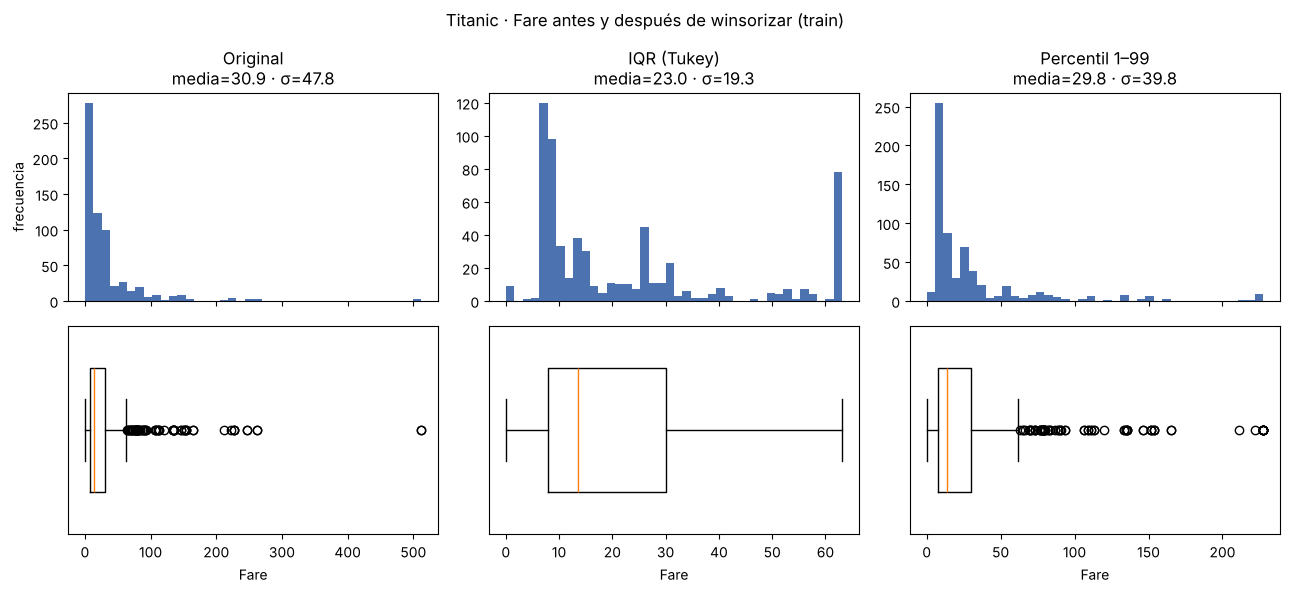

In [21]:
# Pregunta: ¿cómo cambian la distribución y sus estadísticas al recortar Fare?
import matplotlib.pyplot as plt
from src.rol_d import limites_iqr

fare = X_train["Fare"]                                    # límites aprendidos SOLO con train
li_iqr, ls_iqr = limites_iqr(fare)
li_p, ls_p = fare.quantile([0.01, 0.99])
li_iqr = max(li_iqr, fare.min())                          # Fare no puede ser negativa

versiones = {
    "Original":       fare,
    "IQR (Tukey)":    fare.clip(li_iqr, ls_iqr),
    "Percentil 1–99": fare.clip(li_p, ls_p),
}
stats = pd.DataFrame({n: {"media": s.mean(), "mediana": s.median(), "desv. est.": s.std(),
                          "mínimo": s.min(), "máximo": s.max(),
                          "valores recortados": int((s != fare).sum())}
                      for n, s in versiones.items()}).T
print(f"Límites IQR: [{li_iqr:.2f}, {ls_iqr:.2f}]   ·   Límites P1–P99: [{li_p:.2f}, {ls_p:.2f}]")
display(stats.round(2))
stats.to_csv("../resultados/winsorizacion_fare_estadisticas.csv")

fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex="col")
for j, (n, s) in enumerate(versiones.items()):
    axes[0, j].hist(s, bins=40, color="#4c72b0")
    axes[0, j].set_title(f"{n}\nmedia={s.mean():.1f} · σ={s.std():.1f}")
    axes[1, j].boxplot(s, vert=False, widths=.6)
    axes[1, j].set_yticks([]); axes[1, j].set_xlabel("Fare")
axes[0, 0].set_ylabel("frecuencia")
fig.suptitle("Titanic · Fare antes y después de winsorizar (train)")
plt.tight_layout(); plt.savefig("../figuras/d_winsorizacion_fare_antes_despues.png", dpi=150); plt.show()

**Lectura antes/después:**

| Versión | Media | Mediana | Desv. est. | Mín | Máx | Recortados |
|---|---|---|---|---|---|---|
| Original | 30.87 | 13.5 | 47.76 | 0 | 512.33 | — |
| IQR (Tukey) | 22.98 | 13.5 | 19.34 | 0 | 63.16 | 77 |
| Percentil 1–99 | 29.78 | 13.5 | 39.80 | 0 | 227.52 | 6 |

* **La mediana no cambia** en ningún caso: es robusta a los extremos. La media, la desviación estándar y el máximo
  son las que se mueven.
* **IQR es agresivo:** baja la desviación de 47.8 a 19.3 porque recorta 77 tarifas (12 % de train), muchas de
  1ª clase y legítimas; todas quedan amontonadas en 63.16 (la barra alta al final del histograma). Son los mismos
  77 pasajeros que se pierden al eliminar filas (546/623 en la Parte 4).
* **P1–P99 es conservador:** solo toca los 6 casos más extremos (máximo 512 → 228) y conserva la forma de la
  distribución.
* El límite inferior del IQR salía negativo (−25.26); se dejó en el mínimo real (0) porque una tarifa no puede
  ser negativa.

## Parte 5 — Configuración recomendada para el notebook final (Rol A)

```python
from src.rol_d import pipeline_d, preprocesador_d

# Titanic: agregar Titulo antes de dividir (con_titulo está definida en la Parte 2)
X_train, X_test, y_train, y_test = dividir(con_titulo(cargar_datos("titanic")), "titanic")
modelo_tit = pipeline_d(X_train, imputar_num="grupo", grupos=("Titulo",), indicador=True,
                        outliers="log", cols_outliers=["Fare"])

# Credit Card Fraud (sin faltantes; se recortan extremos a P1–P99, sin eliminar filas)
modelo_fr = pipeline_d(Xf_train, outliers="percentil")

# Para combinar con el balanceo del Rol E (SMOTE necesita datos numéricos):
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from src.utils import modelo_base
modelo = ImbPipeline([("prep", preprocesador_d(Xf_train, outliers="percentil")),
                      ("smote", SMOTE(random_state=RANDOM_STATE)),
                      ("modelo", modelo_base())])
```

Archivos generados: `resultados/imputacion_titanic.csv`, `resultados/imputacion_categorica_titanic.csv`,
`resultados/winsorizacion_fare_estadisticas.csv`, `resultados/outliers_titanic.csv`, `resultados/outliers_fraud.csv` y las figuras `figuras/d_*.png`.